# 03 — Exploratory Analysis

Answers the EDA questions in documentation.md §11.2 using the preprocessed channels and the v1 window
features (`flightops.features.build_features`). Those apply the notebook-02 decisions: wrapped heading
as sin/cos, altitude relative to the window end, and median-filtered vertical acceleration.
Duplicate windows are excluded.

In [1]:
%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flightops.config import load_data_config, project_root
from flightops.data.processed import load_processed
from flightops.data.quality import duplicate_mask, parse_flight_record
from flightops.data.schema import FEATURE_NAMES, IDX, LABELS
from flightops.features.build_features import channel_names, load_or_build_features

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
ROOT = project_root()
FIG_DIR = ROOT / "artifacts" / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_COLORS = {0: "#4c72b0", 1: "#dd8452", 2: "#55a868", 3: "#c44e52"}

cfg = load_data_config()
X, y = load_processed()
meta = pd.read_csv(cfg.metadata_path, dtype={"flight_record": str})
meta = meta.join(parse_flight_record(meta["flight_record"]))

F = load_or_build_features(X, ROOT / "data" / "processed")
keep = ~duplicate_mask(X)
F, yk, mk = F[keep].reset_index(drop=True), y[keep], meta[keep].reset_index(drop=True)
print("windows:", len(F), "| features:", F.shape[1], "| channels:", len(channel_names()))

windows: 99740 | features: 230 | channels: 23


## 1. Which variables change most within a window?

Median within-window standard deviation divided by the across-window standard deviation of the window mean, for nominal windows. High values mean the variable mostly varies *during* an approach. Low values mean it mostly differs *between* approaches.

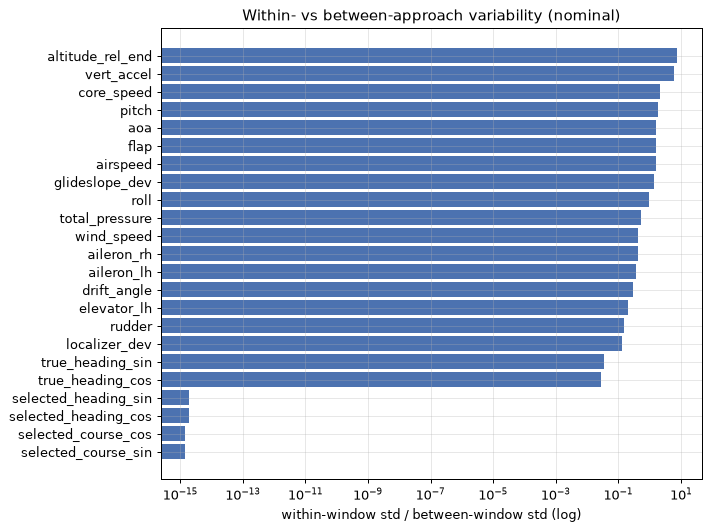

In [2]:
nom = yk == 0
ratio = pd.Series({c: float(np.median(F.loc[nom, f"{c}__std"]) / (F.loc[nom, f"{c}__mean"].std() + 1e-12))
                   for c in channel_names()}).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(ratio.index, ratio.values, color="#4c72b0"); ax.set_xscale("log")
ax.set_xlabel("within-window std / between-window std (log)"); ax.set_title("Within- vs between-approach variability (nominal)")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_variability.png")

## 2. Correlation between variables

Spearman correlation of window means across nominal windows.

rho
selected_heading_cos true_heading_cos      0.978
selected_heading_sin true_heading_sin      0.977
selected_course_cos  selected_heading_cos  0.955
selected_course_sin  selected_heading_sin  0.953
                     true_heading_sin      0.947
selected_course_cos  true_heading_cos      0.946
aoa                  pitch                 0.907
airspeed             flap                 -0.787
flap                 core_speed            0.641
airspeed             core_speed           -0.522

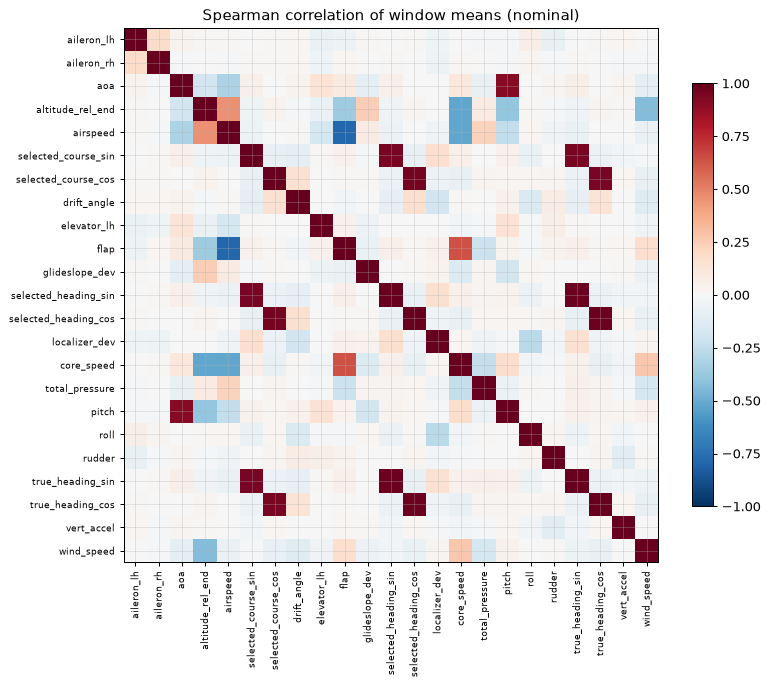

In [3]:
means = F.loc[nom, [f"{c}__mean" for c in channel_names()]]
means.columns = channel_names()
corr = means.sample(20000, random_state=0).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
fig.colorbar(im, shrink=.7); ax.set_title("Spearman correlation of window means (nominal)")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_correlation.png")

pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().rename("rho")
display(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10).round(3).to_frame())

## 3. Which features separate each anomaly class from nominal?

ROC-AUC of each single feature for *class k vs nominal*. 0.5 means no separation. Values far from 0.5 in either direction separate the class (shown as |AUC − 0.5|).

In [4]:
from sklearn.metrics import roc_auc_score
sep = {}
for k in (1, 2, 3):
    m = (yk == 0) | (yk == k)
    t = (yk[m] == k).astype(int)
    sep[LABELS[k]] = pd.Series({c: roc_auc_score(t, F.loc[m, c]) for c in F.columns})
sep = pd.DataFrame(sep)
for k in sep.columns:
    top = (sep[k] - .5).abs().sort_values(ascending=False).head(8).index
    print(f"--- {k}: top single features")
    display(sep.loc[top, [k]].round(3).T)

--- Speed High: top single features


,airspeed__mean,airspeed__iqr,airspeed__slope,airspeed__median,flap__mean,aoa__min,airspeed__std,flap__slope
Speed High,0.796,0.778,0.247,0.752,0.26,0.262,0.738,0.736


--- Path High: top single features


,altitude_rel_end__median,altitude_rel_end__mean,altitude_rel_end__iqr,altitude_rel_end__std,pitch__std,altitude_rel_end__slope,pitch__iqr,core_speed__median
Path High,0.968,0.953,0.934,0.921,0.915,0.087,0.893,0.115


--- Flaps Late Setting: top single features


,flap__median,flap__mean,airspeed__median,airspeed__mean,flap__iqr,flap__slope,airspeed__iqr,flap__std
Flaps Late Setting,0.006,0.023,0.968,0.939,0.927,0.889,0.885,0.873


best single-feature |AUC-0.5| per class: {'Speed High': 0.296, 'Path High': 0.468, 'Flaps Late Setting': 0.494}


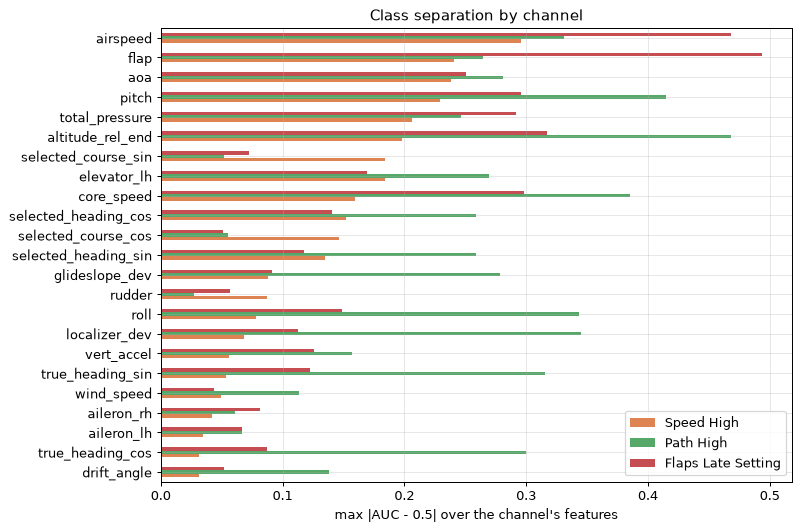

In [5]:
best = (sep - .5).abs().max()
print("best single-feature |AUC-0.5| per class:", best.round(3).to_dict())
by_channel = (sep - .5).abs().groupby(lambda f: f.split("__")[0]).max()
fig, ax = plt.subplots(figsize=(9, 6))
by_channel.sort_values("Speed High").plot.barh(ax=ax, color=[CLASS_COLORS[1], CLASS_COLORS[2], CLASS_COLORS[3]])
ax.set_xlabel("max |AUC - 0.5| over the channel's features"); ax.set_title("Class separation by channel")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_class_separation.png")

## 4. Aircraft 657

Notebook 01 found that aircraft 657 holds about a third of all Speed High labels. The baseline
detects Speed High much less often when 657 is held out. Here its Speed High windows are compared with
Speed High from other aircraft, and with nominal windows.

In [6]:
is657 = (mk["aircraft_id"] == "657").to_numpy()
groups = {"Speed High, aircraft 657": (yk == 1) & is657, "Speed High, other aircraft": (yk == 1) & ~is657,
          "Nominal, aircraft 657": (yk == 0) & is657, "Nominal, other aircraft": (yk == 0) & ~is657}
cols = ["airspeed__max", "airspeed__first", "airspeed__last", "flap__first", "core_speed__mean",
        "glideslope_dev__mean", "altitude_rel_end__first"]
display(pd.DataFrame({g: F.loc[m, cols].median() for g, m in groups.items()}).T.assign(
    n=[int(m.sum()) for m in groups.values()]).round(2))

,airspeed__max,airspeed__first,airspeed__last,flap__first,core_speed__mean,glideslope_dev__mean,altitude_rel_end__first,n
"Speed High, aircraft 657",160.330002,159.639999,108.070000,3019.0,75.769997,0.0,1734.430054,2237
"Speed High, other aircraft",181.350006,178.940002,107.180000,2450.0,73.349998,0.0,1914.910034,4771
"Nominal, aircraft 657",159.710007,158.529999,107.730003,2972.0,76.239998,0.0,1740.270020,279
"Nominal, other aircraft",157.850006,157.399994,108.370003,2997.0,75.910004,0.0,1719.589966,89293


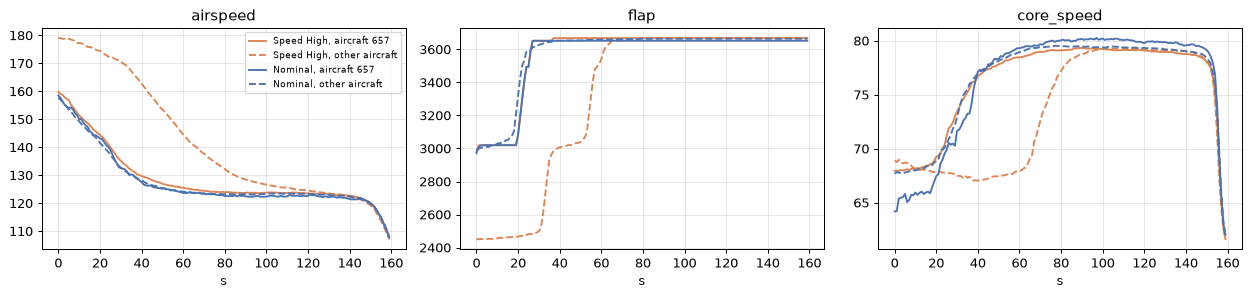

In [7]:
idx_all = np.flatnonzero(keep)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharex=True)
styles = {"Speed High, aircraft 657": ("#dd8452", "-"), "Speed High, other aircraft": ("#dd8452", "--"),
          "Nominal, aircraft 657": ("#4c72b0", "-"), "Nominal, other aircraft": ("#4c72b0", "--")}
rng = np.random.default_rng(0)
for ax, name in zip(axes, ["airspeed", "flap", "core_speed"]):
    for g, m in groups.items():
        sel = np.sort(rng.choice(idx_all[m], size=min(1500, m.sum()), replace=False))
        color, ls = styles[g]
        ax.plot(np.median(X[sel][:, :, IDX[name]], axis=0), color=color, ls=ls, label=g)
    ax.set_title(name); ax.set_xlabel("s")
axes[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(FIG_DIR / "03_aircraft_657.png")

## Findings

1. **Correlated variables.** True heading, selected heading and selected course are almost the same
   signal (ρ > 0.94), and so are angle of attack and pitch (ρ ≈ 0.91). Airspeed is strongly
   anti-correlated with flap position (ρ ≈ −0.79), because flaps extend as the aircraft slows. The
   feature set is redundant, which matters for distance-based models and for explanations.
2. **Each class has a strong single-feature signature:**
   - **Flaps Late:** median flap position (AUC ≈ 0.006, almost perfect separation).
   - **Path High:** median altitude relative to the window end (AUC ≈ 0.97).
   - **Speed High:** mean airspeed (AUC ≈ 0.80). It is the weakest of the three.

   A detector that uses all features equally will dilute these signals.
3. **Aircraft 657's Speed High labels look nominal.** Its Speed High windows have nominal airspeed
   (peak ≈160 kt vs ≈181 kt for Speed High on other aircraft), nominal flap timing and nominal throttle.
   Its trajectories overlap nominal flights almost exactly. Possible explanations are a labelling rule
   tied to an aircraft-specific reference speed, or mislabelled data. The labels can't be verified from
   this dataset.

   **Decision:** report results with and without aircraft 657, and raise the question with the dataset POC.